# 07 — Alibaba GenTD26: Can Sequence Models Forecast GPU Serving Load?

**Revised v2 — residual forecasting and safe input scaling**. The original raw-level setup can underperform persistence because the neural networks must learn the level rather than a correction. This version trains **all learned models** (including CatBoost) to predict the *difference from the last observed GPU utilization*, normalizes that difference using training-only statistics, and fixes constant-feature scaling. It also includes naive baselines in validation-based selection. This is a methodological change; results must be rerun and should not be mixed with the earlier notebook.

**Real-data task:** predict the next **60 minutes of average observed-pod GPU duty-cycle (%)** from the previous **12 hours**, using optional past-only GPU memory and request QPS. Compare MLP, GRU, LSTM, TCN, N-BEATS-*style*, patch Transformer, CatBoost (raw lags and engineered), and naive baselines.

**Source:** [Alibaba GenAI Serving Top-Down Dataset (GenTD26)](https://github.com/alibaba/clusterdata/tree/master/cluster-trace-v2026-GenAI). This release primarily characterizes **Stable Diffusion/multimodal image generation serving**, **not** a broad LLM inference fleet. The data uses anonymized shifted timestamps, GPU utilization is a percentage, and QPS values are scaled. No synthetic observations are used in the actual benchmark.

**Leakage controls:** global chronological 70/15/15 split; no forecast target window crosses split boundaries; train-only normalization (including residual scale); future data limited to deterministic phase of time; QPS and memory are historical only. GPU target timestamps with missing observations are excluded from train/val/test windows rather than treated as zero. Anonymized or shifted times do not establish real local time of day.

**Warning:** container membership can change; a mean over *observed* pods is not a capacity-weighted fleet GPU utilization. One split and one seed are exploratory, not a definitive architectural ranking.

**Setup:** `pip install numpy pandas matplotlib torch catboost nbformat jupyter wandb` (W&B optional). Run from the repository's `Time_Series_Benchmark_Final/` directory; the notebook downloads three small official `.tar.gz` files automatically into `benchmark_data/alibaba_genai/`. Set `USE_WANDB=True` in settings to upload one run per model into project `time-series-forecasting` with dataset group and config filters.

In [1]:
# Settings — start with the real dataset and run all cells. Modify only before model selection.
from pathlib import Path
DATASET_NAME='alibaba_genai_gpu_duty_cycle'
NOTEBOOK_NAME='07_Alibaba_GenAI_GPU_Load.ipynb'
DATA_DIR=Path('benchmark_data/alibaba_genai')
OUTPUT_DIR=Path('forecast_challenge_outputs/alibaba_genai_residual_v2')
INTERVAL_MIN=10
DAY_BINS=24*60//INTERVAL_MIN
LOOKBACK=72           # 12 hours of historical observations
HORIZON=6             # predict next 60 minutes, at 10-min intervals
WINDOW_STRIDE=2
MAX_WINDOWS_PER_SPLIT=8000
SEED=42
MAX_EPOCHS=18
PATIENCE=4
BATCH_SIZE=128
LR=1e-3
CATBOOST_ITERATIONS=350
CATBOOST_PATIENCE=40
USE_WANDB=False       # Turn on to log each training run to W&B
WANDB_PROJECT='time-series-forecasting'
SMOKE_TEST=False      # True only for code checks, never for article scores
METRIC_UNIT='GPU duty-cycle (source-reported units)'  # inspect distribution; documentation calls this a percentage
AUX_COLUMNS=['gpu_mem_log_gib','qps_log','gpu_mem_available','qps_available']
if SMOKE_TEST:
    MAX_EPOCHS=2;CATBOOST_ITERATIONS=15;CATBOOST_PATIENCE=4;MAX_WINDOWS_PER_SPLIT=400
DATA_DIR.mkdir(parents=True,exist_ok=True)

In [2]:
# Shared, self-contained benchmarking engine. No separate .py module is needed.
import copy, json, os, random, time, platform
from contextlib import contextmanager
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from catboost import CatBoostRegressor
from IPython.display import display

DEVICE = torch.device('cuda' if torch.cuda.is_available() else ('mps' if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available() else 'cpu'))
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(min(4,os.cpu_count() or 1))
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
os.environ.setdefault('WANDB_NOTEBOOK_NAME', NOTEBOOK_NAME)
print('device=',DEVICE,'| W&B=',USE_WANDB,'| dataset=',DATASET_NAME)

@contextmanager
def tracked(name, family, extra=None):
    run=None
    if USE_WANDB:
        try:
            import wandb
            cfg=dict(dataset=DATASET_NAME, model=name, family=family, seed=SEED,
                     lookback=LOOKBACK, horizon=HORIZON, sampling_minutes=INTERVAL_MIN,
                     train_fraction=0.70, validation_fraction=0.15,
                     max_epochs=MAX_EPOCHS, learning_rate=LR, smoke_test=SMOKE_TEST,
                     target_transformation='last_observation_residual',
                     input_scaling='train_only_zscore_constant_features_safe')
            cfg.update(extra or {})
            run=wandb.init(project=WANDB_PROJECT, group=DATASET_NAME,
                           name=name.lower().replace(' ','_').replace('(','').replace(')',''),
                           job_type='benchmark', config=cfg, reinit='finish_previous')
        except Exception as ex:
            print('W&B unavailable: ',repr(ex),' | proceeding with local CSVs')
    try: yield run
    finally:
        if run is not None:
            try:run.finish()
            except Exception as ex:print('W&B finalization warning:',repr(ex))

def log_run(run, values, step=None):
    if run is not None:
        try: run.log({k:float(v) for k,v in values.items() if v is not None and np.isfinite(v)},step=step)
        except Exception as ex:print('W&B logging warning:',repr(ex))

def make_windows(panel):
    """Each series has an integer bucket index and 'target' plus optional past covariates.
    Targets/histories must be observed; known future only uses periodic calendar phase.
    Split decisions use the *end* of the forecast target and a global time axis.
    """
    start=min(int(d.index.min()) for d in panel.values())
    end=max(int(d.index.max()) for d in panel.values())+1
    c1=start+int((end-start)*.70)
    c2=start+int((end-start)*.85)
    feature_names=['target']+list(AUX_COLUMNS)
    buckets={'train':[],'val':[],'test':[]}
    for sid, (key, table) in enumerate(sorted(panel.items())):
        # Synchronize to a regular grid. Missing target values remain missing.
        tab=table.reindex(np.arange(int(table.index.min()),int(table.index.max())+1))
        data=tab[feature_names].to_numpy(dtype='float32')
        y=tab['target'].to_numpy(dtype='float32')
        tick=tab.index.to_numpy(dtype=np.int64)
        for t in range(LOOKBACK,len(tab)-HORIZON+1,WINDOW_STRIDE):
            end_bucket=int(tick[t+HORIZON-1]);first_bucket=int(tick[t]);
            if not np.isfinite(y[t-LOOKBACK:t+HORIZON]).all():continue
            if not np.isfinite(data[t-LOOKBACK:t]).all():continue
            block='train' if end_bucket<c1 else ('val' if first_bucket>=c1 and end_bucket<c2 else ('test' if first_bucket>=c2 else None))
            if block is None:continue
            phases=(tick[t:t+HORIZON]-start)%DAY_BINS
            future=np.stack([np.sin(2*np.pi*phases/DAY_BINS),np.cos(2*np.pi*phases/DAY_BINS)],axis=1).astype('float32')
            buckets[block].append((data[t-LOOKBACK:t].copy(),future,y[t:t+HORIZON].copy(),sid,key,int(tick[t])))
    prepared={}
    for split,recs in buckets.items():
        if len(recs)>MAX_WINDOWS_PER_SPLIT:
            selected=np.linspace(0,len(recs)-1,MAX_WINDOWS_PER_SPLIT).round().astype(int)
            recs=[recs[int(i)] for i in selected]
        if not recs:
            raise ValueError(f'No valid {split} windows. Check date coverage, missing bins, and LOOKBACK/HORIZON; counts: '+str({k:len(v) for k,v in buckets.items()}))
        prepared[split]=dict(x=np.stack([r[0] for r in recs]),
                             future=np.stack([r[1] for r in recs]),
                             y=np.stack([r[2] for r in recs]),
                             ids=np.array([r[3] for r in recs],dtype='int64'),
                             keys=[r[4] for r in recs], origins=np.array([r[5] for r in recs]))
    return prepared,len(panel),dict(start=start,end=end,train_cutoff=c1,validation_cutoff=c2,series_count=len(panel))

def standardize(parts):
    """Causal, train-only scaling; predict deviations from last observed load.

    IMPORTANT: A 0/1 availability feature can have zero training variance and change in
    validation. Dividing by 1e-5 makes that flag explode to 100,000. Constant-feature
    channels instead use scale 1.0, and all inputs are clipped to [-10, 10] after
    training-only standardization (the same transformation is applied to every model).

    All forecast models learn (future_gpu - last_observed_gpu)/residual_scale.
    At evaluation, convert back with last_observed_gpu + predicted_delta*residual_scale.
    """
    train = parts['train']
    hx = train['x'].reshape(-1, train['x'].shape[-1])
    h_mu = np.mean(hx, axis=0)
    h_std_raw = np.std(hx, axis=0)
    h_std = np.where(h_std_raw < 1e-3, 1.0, h_std_raw)
    anchor_train = train['x'][:, -1, 0]
    delta_train = train['y'] - anchor_train[:, None]
    residual_scale = max(float(np.std(delta_train)), 1e-3)
    print('Target scaling: train-only future-minus-last residual STD =', round(residual_scale, 5))
    print('Input channel raw STDs:', np.round(h_std_raw, 6).tolist())
    print('Constant-feature channels use divisor 1.0 (not 1e-5).')
    for split, item in parts.items():
        item['x_orig'] = item['x'].copy()
        item['y_orig'] = item['y'].copy()
        item['anchor'] = item['x_orig'][:, -1, 0].astype('float32')
        item['x'] = np.clip((item['x'] - h_mu) / h_std, -10.0, 10.0).astype('float32')
        item['y'] = ((item['y_orig'] - item['anchor'][:, None]) / residual_scale).astype('float32')
        assert np.isfinite(item['x']).all() and np.isfinite(item['y']).all(), split
        persistence = np.broadcast_to(item['anchor'][:, None], item['y_orig'].shape)
        baseline = score(persistence, item['y_orig']) if 'score' in globals() else dict(rmse=float(np.sqrt(np.mean((persistence-item['y_orig'])**2))))
        print(f'{split:5s}: target mean={item["y_orig"].mean():.4f}, target STD={item["y_orig"].std():.4f}, '
              f'persistence RMSE={baseline["rmse"]:.4f}, max |normalized input|={np.max(np.abs(item["x"])):.1f}')
    return float(residual_scale)

def sid_onehot(ids,nseries):
    return np.eye(nseries,dtype=np.float32)[ids]

def flat_features(part,nseries,engineered=False):
    X=np.concatenate([part['x'].reshape(len(part['x']),-1),
                      part['future'].reshape(len(part['x']),-1),sid_onehot(part['ids'],nseries)],axis=1)
    if engineered:
        recent=part['x'][:,:,0]
        extras=np.column_stack([recent.mean(axis=1),recent.std(axis=1),recent.min(axis=1),recent.max(axis=1),
                                recent[:,-3:].mean(axis=1),recent[:,-6:].mean(axis=1),
                                recent[:,-12:].mean(axis=1),recent[:,-1]-recent[:,0]])
        X=np.concatenate([X,extras],axis=1)
    return X.astype('float32')

class MLP(nn.Module):
    def __init__(self,l,f,h,n):
        super().__init__();self.fc=nn.Sequential(nn.Linear(l*f+2*h+n,128),nn.ReLU(),nn.Linear(128,64),nn.ReLU(),nn.Linear(64,h))
    def forward(self,x,t,s):return self.fc(torch.cat([x.flatten(1),t.flatten(1),s],1))
class Recurrent(nn.Module):
    def __init__(self,l,f,h,n,rnn):
        super().__init__();self.rnn=(nn.GRU if rnn=='GRU' else nn.LSTM)(f,48,batch_first=True)
        self.fc=nn.Sequential(nn.Linear(48+2*h+n,80),nn.ReLU(),nn.Linear(80,h))
    def forward(self,x,t,s):
        out,_=self.rnn(x);return self.fc(torch.cat([out[:,-1,:],t.flatten(1),s],1))
class TCN(nn.Module):
    def __init__(self,l,f,h,n):
        super().__init__();layers=[];c=f
        for d in (1,2,4,8):
            layers.extend([nn.ConstantPad1d((2*d,0),0.),nn.Conv1d(c,48,3,dilation=d),nn.ReLU()]);c=48
        self.conv=nn.Sequential(*layers);self.head=nn.Sequential(nn.Linear(48+2*h+n,80),nn.ReLU(),nn.Linear(80,h))
    def forward(self,x,t,s):
        z=self.conv(x.transpose(1,2))[:,:,-1];return self.head(torch.cat([z,t.flatten(1),s],1))
class NBEATSBlock(nn.Module):
    def __init__(self,in_dim,h):
        super().__init__();self.fc=nn.Sequential(nn.Linear(in_dim,128),nn.ReLU(),nn.Linear(128,128),nn.ReLU())
        self.back=nn.Linear(128,in_dim);self.fore=nn.Linear(128,h)
    def forward(self,x):
        z=self.fc(x);return self.back(z),self.fore(z)
class NBEATSStyle(nn.Module):
    def __init__(self,l,f,h,n):
        super().__init__();self.blocks=nn.ModuleList([NBEATSBlock(l*f,h) for _ in range(3)])
        self.known=nn.Linear(2*h+n,h)
    def forward(self,x,t,s):
        resid=x.flatten(1); forecast=0
        for b in self.blocks:
            back,fore=b(resid);resid=resid-back;forecast=forecast+fore
        return forecast+self.known(torch.cat([t.flatten(1),s],1))
class PatchTransformer(nn.Module):
    def __init__(self,l,f,h,n):
        super().__init__();self.patch=6;self.pad=(-l)%self.patch
        self.proj=nn.Linear(f*self.patch,48)
        layer=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,dropout=.0,batch_first=True)
        self.encoder=nn.TransformerEncoder(layer, num_layers=2)
        self.head=nn.Sequential(nn.Linear(48+2*h+n,80),nn.ReLU(),nn.Linear(80,h))
    def forward(self,x,t,s):
        if self.pad:x=nn.functional.pad(x,(0,0,self.pad,0))
        z=x.reshape(x.shape[0],-1,self.patch*x.shape[-1]);z=self.encoder(self.proj(z)).mean(dim=1)
        return self.head(torch.cat([z,t.flatten(1),s],1))

def model_factory(name,l,f,h,n):
    return {'MLP':lambda:MLP(l,f,h,n), 'GRU':lambda:Recurrent(l,f,h,n,'GRU'),
            'LSTM':lambda:Recurrent(l,f,h,n,'LSTM'), 'TCN':lambda:TCN(l,f,h,n),
            'N-BEATS-style':lambda:NBEATSStyle(l,f,h,n),
            'Patch Transformer':lambda:PatchTransformer(l,f,h,n)}[name]()

def score(yhat,y):
    return dict(rmse=float(np.sqrt(np.mean((yhat-y)**2))),mae=float(np.mean(np.abs(yhat-y))))

def run_benchmark(parts,nseries,metadata, residual_scale):
    l=LOOKBACK;f=parts['train']['x'].shape[2];h=HORIZON;n=nseries
    xparts={}
    for k,v in parts.items():
        xparts[k]=(torch.from_numpy(v['x']).float(),torch.from_numpy(v['future']).float(),
                   torch.from_numpy(sid_onehot(v['ids'],n)).float(),torch.from_numpy(v['y']).float())
    result=[];predictions={};epoch_history=[]
    names=['MLP','GRU','LSTM','TCN','N-BEATS-style','Patch Transformer']
    if SMOKE_TEST:print('SMOKE TEST: output scores are NOT for publication')
    for name in names:
        torch.manual_seed(SEED);random.seed(SEED);np.random.seed(SEED)
        model=model_factory(name,l,f,h,n).to(DEVICE)
        opt=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=1e-4)
        train_loader=DataLoader(TensorDataset(*xparts['train']),batch_size=BATCH_SIZE,shuffle=True)
        best=float('inf');best_state=None;best_epoch=0;wait=0;tic=time.perf_counter()
        with tracked(name,'Neural',dict(parameters=sum(p.numel() for p in model.parameters()))) as wr:
            for ep in range(1,MAX_EPOCHS+1):
                model.train();losses=[]
                for bx,bt,bs,by in train_loader:
                    bx,bt,bs,by=(z.to(DEVICE) for z in (bx,bt,bs,by))
                    opt.zero_grad();out=model(bx,bt,bs);loss=(out-by).square().mean();loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(),1.);opt.step();losses.append(loss.item())
                model.eval()
                with torch.no_grad():
                    xv,tv,sv,yv=(z.to(DEVICE) for z in xparts['val'])
                    val_pred=model(xv,tv,sv)
                    val_loss=float((val_pred-yv).square().mean().item())
                epoch_history.append(dict(model=name,epoch=ep,train_mse=np.mean(losses),validation_mse=val_loss))
                log_run(wr,{'train/residual_mse':np.mean(losses),'validation/residual_mse':val_loss,'validation/rmse':np.sqrt(val_loss)*residual_scale},step=ep)
                if val_loss<best-1e-7:best=val_loss;best_state=copy.deepcopy(model.state_dict());best_epoch=ep;wait=0
                else:wait+=1
                if wait>=PATIENCE:break
            model.load_state_dict(best_state);model.eval()
            with torch.no_grad():
                xte,tte,ste,_=(z.to(DEVICE) for z in xparts['test'])
                pred=model(xte,tte,ste).cpu().numpy()*residual_scale+parts['test']['anchor'][:,None]
            predictions[name]=pred
            vals=score(pred,parts['test']['y_orig'])
            row=dict(model=name,family='Neural',val_rmse=np.sqrt(best)*residual_scale,**vals,
                     best_epoch=best_epoch,train_seconds=time.perf_counter()-tic,parameters=sum(p.numel() for p in model.parameters()))
            result.append(row)
            log_run(wr,{'test/rmse':vals['rmse'],'test/mae':vals['mae'],'validation/rmse_best':row['val_rmse'],'train/seconds':row['train_seconds']})
        print(f'{name:20} val={row["val_rmse"]:.3f} test={row["rmse"]:.3f} {METRIC_UNIT} epoch={best_epoch}',flush=True)
        del model
        if DEVICE.type=='cuda':torch.cuda.empty_cache()
    for engineered in (False,True):
        name='CatBoost (engineered)' if engineered else 'CatBoost (raw lags)'
        tic=time.perf_counter()
        Xtr=flat_features(parts['train'],n,engineered);Xva=flat_features(parts['val'],n,engineered);Xte=flat_features(parts['test'],n,engineered)
        with tracked(name,'Tree',dict(engineered_features=engineered,catboost_iterations=CATBOOST_ITERATIONS)) as wr:
            cb=CatBoostRegressor(loss_function='MultiRMSE',iterations=CATBOOST_ITERATIONS,depth=6,learning_rate=.06,
                                 l2_leaf_reg=3,random_seed=SEED,thread_count=min(4,os.cpu_count() or 1),
                                 allow_writing_files=False,verbose=False)
            cb.fit(Xtr,parts['train']['y'],eval_set=(Xva,parts['val']['y']),
                   early_stopping_rounds=CATBOOST_PATIENCE,use_best_model=True,verbose=False)
            p=cb.predict(Xte)*residual_scale+parts['test']['anchor'][:,None]
            pred=np.asarray(p,dtype=float);predictions[name]=pred
            val_pred=cb.predict(Xva)*residual_scale+parts['val']['anchor'][:,None]
            va=score(val_pred,parts['val']['y_orig']);te=score(pred,parts['test']['y_orig'])
            row=dict(model=name,family='Tree',val_rmse=va['rmse'],**te,best_epoch=cb.tree_count_,
                     train_seconds=time.perf_counter()-tic,parameters=np.nan)
            result.append(row)
            log_run(wr,{'test/rmse':te['rmse'],'test/mae':te['mae'],'validation/rmse_best':va['rmse'],'train/seconds':row['train_seconds']})
        print(f'{name:20} val={row["val_rmse"]:.3f} test={row["rmse"]:.3f} {METRIC_UNIT}',flush=True)
    # Baselines: last observation; seasonal (when history permits).
    for name,offset in [('Last observed',1),('Previous day',DAY_BINS)]:
        if offset>LOOKBACK:continue
        for partition in ['val','test']:
            p=parts[partition];sample=p['x_orig'][:,: ,0]
            if offset==1: pred=np.repeat(sample[:,-1:],HORIZON,axis=1)
            else:
                if HORIZON>offset:continue
                pred=sample[:,-offset:-offset+HORIZON]
            if partition=='val': v=score(pred,p['y_orig'])
            else:te=score(pred,p['y_orig']);predictions[name]=pred
        row=dict(model=name,family='Naive',val_rmse=v['rmse'],**te,best_epoch=np.nan,train_seconds=0.,parameters=np.nan)
        result.append(row)
    comp=pd.DataFrame(result).sort_values('rmse').reset_index(drop=True)
    display(comp.round(4));comp.to_csv(OUTPUT_DIR/'comparison.csv',index=False)
    pd.DataFrame(epoch_history).to_csv(OUTPUT_DIR/'epoch_history.csv',index=False)
    metadata.update(dict(dataset=DATASET_NAME,seed=SEED,lookback=LOOKBACK,horizon=HORIZON,
                         interval_minutes=INTERVAL_MIN,train_windows=len(parts['train']['x']),
                         val_windows=len(parts['val']['x']),test_windows=len(parts['test']['x']),
                         smoke_test=SMOKE_TEST,feature_columns=['target']+list(AUX_COLUMNS),
                         neural_epochs=MAX_EPOCHS,catboost_max_iterations=CATBOOST_ITERATIONS,
                         model_names=comp['model'].tolist(),metric='RMSE',unit=METRIC_UNIT,
                         target_transformation='last_observed_plus_scaled_predicted_delta',
                         train_only_delta_std=float(residual_scale),
                         input_scaling='train_only_zscore_constant_features_scale_one_clip_10',
                         python=platform.python_version(),torch=torch.__version__,catboost=__import__('catboost').__version__))
    (OUTPUT_DIR/'run_info.json').write_text(json.dumps(metadata,indent=2,default=str),encoding='utf8')
    # Save predictions in lightweight long form; maintain sample origin and series key.
    records=[]
    for name,pred in predictions.items():
        for i in range(len(pred)):
            for hh in range(HORIZON):
                records.append((name,parts['test']['keys'][i],int(parts['test']['origins'][i]),hh+1,
                                float(parts['test']['y_orig'][i,hh]),float(pred[i,hh])))
    pd.DataFrame(records,columns=['model','series_id','forecast_origin_bucket','horizon_step','actual','prediction']).to_csv(OUTPUT_DIR/'test_predictions.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,5))
    ax.barh(comp['model'][::-1],comp['rmse'][::-1]);ax.set(xlabel=f'Test RMSE ({METRIC_UNIT}); lower is better',title=DATASET_NAME+' | Compute-load forecasting')
    fig.tight_layout();fig.savefig(OUTPUT_DIR/'rmse_ranking.png',dpi=180);plt.show()
    choice=comp.sort_values('val_rmse').iloc[0]  # All models, including naive, eligible
    learned_choice=comp.query('family!="Naive"').sort_values('val_rmse').iloc[0]
    test_best=comp.iloc[0]
    print(f'Validation-selected OVERALL: {choice["model"]} -> held-out test RMSE={choice["rmse"]:.4f}')
    print(f'Validation-selected LEARNED model: {learned_choice["model"]} -> held-out test RMSE={learned_choice["rmse"]:.4f}')
    print(f'Post-hoc lowest test error: {test_best["model"]} ({test_best["rmse"]:.4f})')
    print('One split, one seed, limited tuning. Use validation for selection; treat test ranking as descriptive.')
    print('Saved:',OUTPUT_DIR.resolve())
    return comp

device= mps | W&B= False | dataset= alibaba_genai_gpu_duty_cycle


## Load official trace and construct leak-free aligned time bins

In [3]:
# Small public GitHub release archives; the notebook downloads only 3 relevant metrics.
# Dataset: GenTD26 (mostly a Stable Diffusion serving system; *not* a general LLM cluster trace).
import io, tarfile, urllib.request
ARCHIVES={
    'gpu':'pod_gpu_duty_cycle_anon.tar.gz',
    'memory':'pod_gpu_memory_used_bytes_anon.tar.gz',
    'qps':'qps.tar.gz',
}
ROOT='https://raw.githubusercontent.com/alibaba/clusterdata/master/cluster-trace-v2026-GenAI/'

def load_archive(key, archive):
    path=DATA_DIR/archive
    if not path.exists():
        print('Downloading',archive)
        urllib.request.urlretrieve(ROOT+archive,str(path))
    with tarfile.open(path,'r:gz') as tf:
        files=[m for m in tf.getmembers() if m.isfile() and m.name.endswith('.csv')]
        if not files:raise RuntimeError(f'No CSV found in {path}; check the upstream archive contents')
        frames=[pd.read_csv(tf.extractfile(m),low_memory=False) for m in files]
    df=pd.concat(frames,ignore_index=True)
    df.columns=[str(x).strip().lower() for x in df.columns]
    required={'timestamp_anon','value','container_ip'}
    if not required.issubset(df.columns):
        raise ValueError(f'Unexpected {archive} columns: {list(df.columns)}; expected {sorted(required)}')
    df['timestamp_anon']=pd.to_numeric(df['timestamp_anon'],errors='coerce')
    df['value']=pd.to_numeric(df['value'],errors='coerce')
    df=df.dropna(subset=['timestamp_anon','value']).copy()
    df['bucket']=np.floor(df['timestamp_anon']/float(INTERVAL_MIN*60)).astype('int64')
    df['container_ip']=df['container_ip'].fillna('__unlabeled__').astype(str)
    if key=='qps':
        # Average repeated samples per container/request type, THEN sum QPS across containers.
        if 'request_type' in df: df['container_ip']+='|'+df['request_type'].fillna('unknown').astype(str)
    by_container=df.groupby(['bucket','container_ip'],observed=True)['value'].mean()
    agg=by_container.groupby(level=0).sum() if key=='qps' else by_container.groupby(level=0).mean()
    print(f'{archive}: {len(df):,} raw records, {len(agg):,} time bins')
    return agg.rename(key)

gpu=load_archive('gpu',ARCHIVES['gpu'])
mem=load_archive('memory',ARCHIVES['memory'])
qps=load_archive('qps',ARCHIVES['qps'])
frame=pd.concat([gpu,mem,qps],axis=1).sort_index()
frame=frame.reindex(np.arange(int(gpu.index.min()),int(gpu.index.max())+1))
frame['target']=frame['gpu']
# Covariate missingness is observed, never interpreted as true zero traffic/memory.
train_end=frame.index.min()+int(len(frame)*.70)
for col in ['memory','qps']:
    observed=frame[col].notna()
    med=frame.loc[(frame.index<train_end)&observed,col].median()
    if not np.isfinite(med):med=0.
    frame[col]=frame[col].fillna(med).clip(lower=0)
    frame['gpu_mem_available' if col=='memory' else 'qps_available']=observed.astype('float32')
frame['gpu_mem_log_gib']=np.log1p(frame['memory']/2**30)
frame['qps_log']=np.log1p(frame['qps'])
panel={'cluster_observed_pods':frame[['target']+AUX_COLUMNS]}
print('Time bins:',len(frame),'observed GPU bins:',int(frame.target.notna().sum()),
      'overall coverage:',round(frame.target.notna().mean(),3))
print('Sampling composition varies by bin; the target is mean utilization across *observed* pods, not fleet-weighted total GPU demand.')
parts,nseries,meta=make_windows(panel)
residual_scale=standardize(parts)
print('Train/validation/test window counts:',*(len(parts[k]['x']) for k in ['train','val','test']))
assert nseries==1

pod_gpu_duty_cycle_anon.tar.gz: 157,417 raw records, 138 time bins
pod_gpu_memory_used_bytes_anon.tar.gz: 161,413 raw records, 138 time bins
qps.tar.gz: 24,627 raw records, 123 time bins
Time bins: 138 observed GPU bins: 138 overall coverage: 1.0
Sampling composition varies by bin; the target is mean utilization across *observed* pods, not fleet-weighted total GPU demand.
Target scaling: train-only future-minus-last residual STD = 2.45167
Input channel raw STDs: [5.439545154571533, 0.06153799965977669, 0.46610400080680847, 0.0, 0.0]
Constant-feature channels use divisor 1.0 (not 1e-5).
train: target mean=3.7303, target STD=1.8835, persistence RMSE=2.5673, max |normalized input|=4.3
val  : target mean=1.7152, target STD=1.3635, persistence RMSE=1.8581, max |normalized input|=4.1
test : target mean=1.4989, target STD=1.3898, persistence RMSE=2.0490, max |normalized input|=4.3
Train/validation/test window counts: 10 8 8


## Fit and evaluate the complete benchmark

MLP                  val=1.930 test=2.120 GPU duty-cycle (source-reported units) epoch=1
GRU                  val=1.877 test=2.045 GPU duty-cycle (source-reported units) epoch=1
LSTM                 val=1.872 test=2.047 GPU duty-cycle (source-reported units) epoch=1
TCN                  val=1.850 test=2.055 GPU duty-cycle (source-reported units) epoch=1
N-BEATS-style        val=2.073 test=2.603 GPU duty-cycle (source-reported units) epoch=1
Patch Transformer    val=1.858 test=2.134 GPU duty-cycle (source-reported units) epoch=1
CatBoost (raw lags)  val=2.058 test=2.147 GPU duty-cycle (source-reported units)
CatBoost (engineered) val=1.935 test=2.117 GPU duty-cycle (source-reported units)


,model,family,val_rmse,rmse,mae,best_epoch,train_seconds,parameters
0,GRU,Neural,1.8772,2.0449,1.6066,1.0,0.8237,13366.0
1,LSTM,Neural,1.8715,2.0471,1.6076,1.0,0.4956,16006.0
2,Last observed,Naive,1.8581,2.0490,1.5866,NaN,0.0000,NaN
3,TCN,Neural,1.8499,2.0553,1.6129,1.0,0.5399,27094.0
4,CatBoost (engineered),Tree,1.9346,2.1174,1.7415,333.0,0.7204,NaN
5,MLP,Neural,1.9301,2.1203,1.7514,1.0,1.0038,56518.0
6,Patch Transformer,Neural,1.8579,2.1335,1.6806,1.0,0.7044,44854.0
7,CatBoost (raw lags),Tree,2.0575,2.1466,1.7787,16.0,0.1736,NaN
8,N-BEATS-style,Neural,2.0726,2.6034,2.2849,1.0,0.6463,329886.0


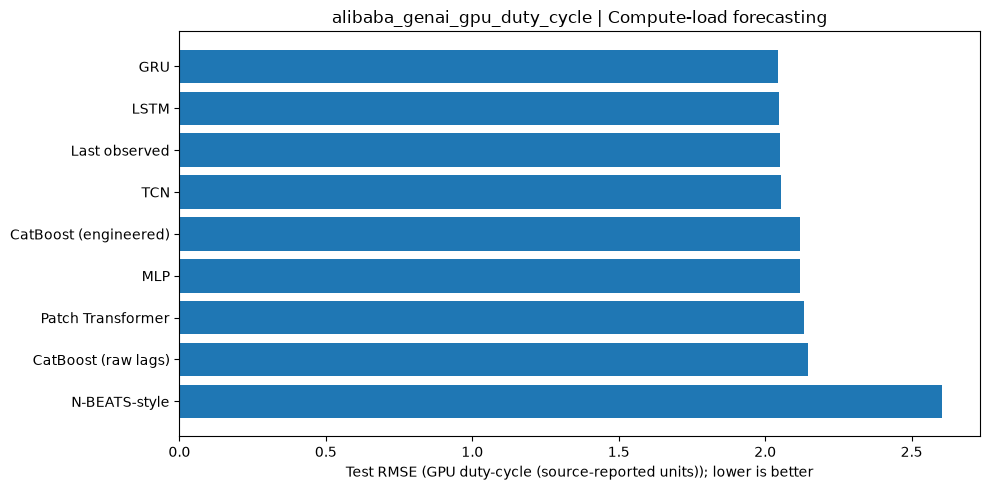

Validation-selected OVERALL: TCN -> held-out test RMSE=2.0553
Validation-selected LEARNED model: TCN -> held-out test RMSE=2.0553
Post-hoc lowest test error: GRU (2.0449)
One split, one seed, limited tuning. Use validation for selection; treat test ranking as descriptive.
Saved: /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/forecast_challenge_outputs/alibaba_genai_residual_v2


In [4]:
comparison=run_benchmark(parts,nseries,meta,residual_scale)

## Reading the results

The notebook exports `comparison.csv`, `epoch_history.csv`, `run_info.json`, `test_predictions.csv`, and `rmse_ranking.png` under `forecast_challenge_outputs/alibaba_genai_residual_v2/`. Validation chooses configurations. Test rankings are descriptive; never choose hyperparameters based on test RMSE.

**Evaluation caveat:** forecasting the mean across currently observed pods can be easier or harder than forecasting an individual fixed GPU; changes in observed pod composition and irregular telemetry remain confounders. Compare **within this dataset**; RMSE percentage points are not directly comparable to MASE on Tourism or M4. The `N-BEATS-style` and `Patch Transformer` models are compact implementations, not exact reproductions of research baselines.

**Citation:** Lin et al., *Understanding Diffusion Model Serving in Production: A Top-Down Analysis of Workload, Scheduling, and Resource Efficiency*, SoCC 2025, as requested in the dataset README.

### Why this revision is different

- The original neural networks estimated absolute GPU duty-cycle, whereas a last-observed baseline automatically copies the latest load. That is not a unit-conversion error, but is an important modeling asymmetry when utilization is persistent. **All learned models now predict deviations from persistence**, using a common target scale fitted on training only. This is a new experimental configuration; rerun the benchmark and preserve both result versions.
- Near-zero-variance binary availability features no longer explode to enormous standardized values in validation or test. Train-only clipping provides an additional guardrail against out-of-distribution auxiliary measurements.
- **Validation now compares the naive models too.** The printed output distinguishes the best validation-selected model overall, the best validation-selected learned model, and the descriptive post-hoc test leader.
- A persistence forecast may legitimately remain the strongest performer. That would be a useful infrastructure forecasting result, not evidence of broken model training.
- Review the printed target ranges and persistence RMSE before drawing conclusions. Without the user's original real-data run outputs, we cannot attribute the earlier score gap solely to scaling.
